# Online Shopping Clickstream & Customer Behavior Analysis using Python

**Name:** Anunay Kumar Sah
**Dataset:** UCI Clickstream Data for Online Shopping (https://archive.ics.uci.edu/dataset/553/clickstream+data+for+online+shopping)
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

## Objective
An e-commerce company wants to understand how users interact with its website and find patterns in online shopping behaviour. The data is a log of clicks on an online clothing store (April to August 2008). In this notebook I clean the data, explore it, and try to answer these questions:

1. Which product categories receive the most attention?
2. Which pages attract the most clicks?
3. Does product price affect user behaviour?
4. Which countries generate the most activity?
5. What are the most frequently visited page locations?
6. Are there differences in behaviour across product categories?
7. What patterns can be identified between browsing activity and purchasing behaviour?
8. Which variables appear to be associated with customer conversion?
9. Are there unusual user behaviours or outliers?



## 1. Data Understanding

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
pd.options.display.float_format = "{:,.2f}".format

# folder to save my charts (needed later for the report and slides)
os.makedirs("figures", exist_ok=True)

In [ ]:
# --- LOAD ---
# A file picker will appear below. Choose the csv file (e-shop clothing 2008.csv) from your computer.
from google.colab import files
uploaded = files.upload()

file_name = list(uploaded.keys())[0]
df_raw = pd.read_csv(file_name, sep=";")    # this file uses ; as separator

print(df_raw.shape)
df_raw.head()

Saving e-shop_clothing_2008[1].csv to e-shop_clothing_2008[1].csv
(165474, 14)


,year,month,day,order,country,session ID,page 1 (main category),page 2 (clothing model),colour,location,model photography,price,price 2,page
0,2008,4,1,1,29,1,1,A13,1,5,1,28,2,1
1,2008,4,1,2,29,1,1,A16,1,6,1,33,2,1
2,2008,4,1,3,29,1,2,B4,10,2,1,52,1,1
3,2008,4,1,4,29,1,2,B17,6,6,2,38,2,1
4,2008,4,1,5,29,1,2,B8,4,3,2,52,1,1


In [ ]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 165474 entries, 0 to 165473
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype 
---  ------                   --------------   ----- 
 0   year                     165474 non-null  int64 
 1   month                    165474 non-null  int64 
 2   day                      165474 non-null  int64 
 3   order                    165474 non-null  int64 
 4   country                  165474 non-null  int64 
 5   session ID               165474 non-null  int64 
 6   page 1 (main category)   165474 non-null  int64 
 7   page 2 (clothing model)  165474 non-null  object
 8   colour                   165474 non-null  int64 
 9   location                 165474 non-null  int64 
 10  model photography        165474 non-null  int64 
 11  price                    165474 non-null  int64 
 12  price 2                  165474 non-null  int64 
 13  page                     165474 non-null  int64 
dtypes: int64(13), object

In [ ]:
df_raw.describe()

,year,month,day,order,country,session ID,page 1 (main category),colour,location,model photography,price,price 2,page
count,"165,474.00","165,474.00","165,474.00","165,474.00","165,474.00","165,474.00","165,474.00","165,474.00","165,474.00","165,474.00","165,474.00","165,474.00","165,474.00"
mean,"2,008.00",5.59,14.52,9.82,26.95,"12,058.42",2.40,6.23,3.26,1.26,43.80,1.49,1.71
std,0.00,1.33,8.83,13.48,7.15,"7,008.42",1.14,4.24,1.71,0.44,12.55,0.50,0.98
min,"2,008.00",4.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,18.00,1.00,1.00
25%,"2,008.00",4.00,7.00,2.00,29.00,"5,931.00",1.00,3.00,2.00,1.00,33.00,1.00,1.00
50%,"2,008.00",5.00,14.00,6.00,29.00,"11,967.50",2.00,4.00,3.00,1.00,43.00,1.00,1.00
75%,"2,008.00",7.00,22.00,12.00,29.00,"18,219.00",3.00,9.00,5.00,2.00,52.00,2.00,2.00
max,"2,008.00",8.00,31.00,195.00,47.00,"24,026.00",4.00,14.00,6.00,2.00,82.00,2.00,5.00


### Data dictionary

| Column | Meaning |
|---|---|
| year, month, day | Date of the click (April to August 2008) |
| order | Sequence number of the click inside one session (1 = first click) |
| country | Country of the IP address (coded 1-47) |
| session ID | Id of the session (one visit of one user) |
| page 1 (main category) | 1 trousers, 2 skirts, 3 blouses, 4 sale |
| page 2 (clothing model) | Product code (217 different products) |
| colour | Colour of the product (coded 1-14) |
| location | Position of the photo on the page: 1 top left, 2 top middle, 3 top right, 4 bottom left, 5 bottom middle, 6 bottom right |
| model photography | 1 = photo from the front (en face), 2 = profile |
| price | Price in US dollars |
| price 2 | 1 = price is higher than the average price of the category, 2 = not higher |
| page | Page number inside the shop (1 to 5) |

Each row is **one click on one product**, not one customer. Many rows with the same `session ID` make one visit. So later I group rows by session to study how users behave during a visit.

## 2. Data Cleaning

### 2.1 Missing values, duplicates and column names

In [ ]:
print("Missing values:", df_raw.isnull().sum().sum())
print("Duplicate rows:", df_raw.duplicated().sum())

df = df_raw.copy()
df.columns = ["year", "month", "day", "order", "country", "session", "category",
              "model", "colour", "location", "photo", "price", "price2", "page"]
df["model"] = df["model"].astype(str)
df = df.sort_values(["session", "order"]).reset_index(drop=True)
df.head()

Missing values: 0
Duplicate rows: 0


,year,month,day,order,country,session,category,model,colour,location,photo,price,price2,page
0,2008,4,1,1,29,1,1,A13,1,5,1,28,2,1
1,2008,4,1,2,29,1,1,A16,1,6,1,33,2,1
2,2008,4,1,3,29,1,2,B4,10,2,1,52,1,1
3,2008,4,1,4,29,1,2,B17,6,6,2,38,2,1
4,2008,4,1,5,29,1,2,B8,4,3,2,52,1,1


There are no missing values and no duplicate rows, so nothing needs to be filled or removed here. I renamed the columns to shorter names to make the code easier to write.

### 2.2 Checking that the data makes sense

In [ ]:
# 1) click order in a session should be 1, 2, 3 ... without gaps
check = df.groupby("session")["order"].agg(["max", "count"])
print("Sessions with a broken click sequence:", (check["max"] != check["count"]).sum())
print("Duplicate (session, order) rows:", df.duplicated(["session", "order"]).sum())

# 2) does one session always have one country and one date?
print("Sessions with more than one country:", (df.groupby("session")["country"].nunique() > 1).sum())

Sessions with a broken click sequence: 0
Duplicate (session, order) rows: 0
Sessions with more than one country: 0


In [ ]:
# 3) product code starts with a letter that should match the category
# A = trousers, B = skirts, C = blouses, P = sale
prefix_to_category = {"A": 1, "B": 2, "C": 3, "P": 4}
df["expected_category"] = df["model"].str[0].map(prefix_to_category)

print("Rows where the product code does not match the category:", (df["expected_category"] != df["category"]).sum())
df[df["expected_category"] != df["category"]]

Rows where the product code does not match the category: 1


,year,month,day,order,country,session,category,model,colour,location,photo,price,price2,page,expected_category
19001,2008,4,10,27,29,2766,2,A18,4,6,1,38,2,1,1


In [ ]:
# one wrong row only, so I remove it
df = df[df["expected_category"] == df["category"]].drop(columns="expected_category")
print("Rows now:", len(df))

Rows now: 165473


In [ ]:
# 4) price2 says if the price is higher than the category average. Check that it is consistent.
df.groupby(["category", "price2"])["price"].agg(["min", "max", "mean"])

min  max  mean
category price2                
1        1        48   82 64.79
         2        28   43 37.32
2        1        52   67 57.64
         2        33   48 39.62
3        1        43   77 49.10
         2        18   38 28.58
4        1        38   65 41.75
         2        23   33 29.71

Inside every category, all products with `price2 = 1` (higher than average) are more expensive than the ones with `price2 = 2`, so this column is consistent with the price.

### 2.3 Create new columns

In [ ]:
# real date and weekday from year, month, day
df["date"] = pd.to_datetime(df[["year", "month", "day"]])
df["weekday"] = df["date"].dt.day_name()

# replace the codes with real names (from the data description file)
country_names = {1: "Australia", 2: "Austria", 3: "Belgium", 4: "British Virgin Islands", 5: "Cayman Islands",
    6: "Christmas Island", 7: "Croatia", 8: "Cyprus", 9: "Czech Republic", 10: "Denmark", 11: "Estonia",
    12: "Unidentified", 13: "Faroe Islands", 14: "Finland", 15: "France", 16: "Germany", 17: "Greece",
    18: "Hungary", 19: "Iceland", 20: "India", 21: "Ireland", 22: "Italy", 23: "Latvia", 24: "Lithuania",
    25: "Luxembourg", 26: "Mexico", 27: "Netherlands", 28: "Norway", 29: "Poland", 30: "Portugal",
    31: "Romania", 32: "Russia", 33: "San Marino", 34: "Slovakia", 35: "Slovenia", 36: "Spain",
    37: "Sweden", 38: "Switzerland", 39: "Ukraine", 40: "United Arab Emirates", 41: "United Kingdom",
    42: "USA", 43: ".biz", 44: ".com", 45: ".int", 46: ".net", 47: ".org"}
category_names = {1: "Trousers", 2: "Skirts", 3: "Blouses", 4: "Sale"}
colour_names = {1: "Beige", 2: "Black", 3: "Blue", 4: "Brown", 5: "Burgundy", 6: "Gray", 7: "Green",
    8: "Navy blue", 9: "Many colours", 10: "Olive", 11: "Pink", 12: "Red", 13: "Violet", 14: "White"}
location_names = {1: "Top left", 2: "Top middle", 3: "Top right", 4: "Bottom left", 5: "Bottom middle", 6: "Bottom right"}
photo_names = {1: "En face", 2: "Profile"}
price2_names = {1: "Above category average", 2: "Not above average"}

df["country_name"] = df["country"].map(country_names)
df["category_name"] = df["category"].map(category_names)
df["colour_name"] = df["colour"].map(colour_names)
df["location_name"] = df["location"].map(location_names)
df["photo_name"] = df["photo"].map(photo_names)
df["price_group"] = df["price2"].map(price2_names)

location_order = ["Top left", "Top middle", "Top right", "Bottom left", "Bottom middle", "Bottom right"]
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

print("Clicks:", len(df))
print("Sessions:", df["session"].nunique())
print("Products:", df["model"].nunique())
print("Countries:", df["country"].nunique())
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())

Clicks: 165473
Sessions: 24026
Products: 217
Countries: 47
Date range: 2008-04-01 to 2008-08-13


### 2.4 Session-level data

In [ ]:
# helper columns
df["is_above_avg"] = (df["price2"] == 1).astype(int)
df["is_sale"] = (df["category"] == 4).astype(int)

sessions = df.groupby("session").agg(
    clicks=("order", "max"),
    pages=("page", "max"),
    products=("model", "nunique"),
    categories=("category", "nunique"),
    avg_price=("price", "mean"),
    above_avg_share=("is_above_avg", "mean"),
    sale_share=("is_sale", "mean"),
    first_category=("category", "first"),
    country_name=("country_name", "first"),
    date=("date", "first"),
    weekday=("weekday", "first"),
    month=("month", "first")
).reset_index()

sessions["first_category_name"] = sessions["first_category"].map(category_names)
sessions.head()

,session,clicks,pages,products,categories,avg_price,above_avg_share,sale_share,first_category,country_name,date,weekday,month,first_category_name
0,1,9,5,9,4,42.11,0.56,0.22,1,Poland,2008-04-01,Tuesday,4,Trousers
1,2,10,2,8,3,50.00,0.80,0.30,2,Poland,2008-04-01,Tuesday,4,Skirts
2,3,6,5,6,3,42.17,0.67,0.17,2,Ireland,2008-04-01,Tuesday,4,Skirts
3,4,4,3,4,2,45.25,0.50,0.00,1,Ireland,2008-04-01,Tuesday,4,Trousers
4,5,1,2,1,1,57.00,1.00,0.00,3,Czech Republic,2008-04-01,Tuesday,4,Blouses


In [ ]:
sessions[["clicks", "pages", "products", "categories", "avg_price"]].describe()

,clicks,pages,products,categories,avg_price
count,"24,026.00","24,026.00","24,026.00","24,026.00","24,026.00"
mean,6.89,2.25,6.17,1.85,44.37
std,9.00,1.28,7.53,0.96,8.45
min,1.00,1.00,1.00,1.00,18.00
25%,2.00,1.00,2.00,1.00,38.17
50%,4.00,2.00,4.00,2.00,43.67
75%,8.00,3.00,8.00,3.00,49.00
max,195.00,5.00,168.00,4.00,82.00


- The average session has about 7 clicks but the median is only 4, so a small number of very long sessions pull the average up.


In [ ]:
print("Sessions with only 1 click:", round((sessions["clicks"] == 1).mean() * 100, 1), "%")
print("Sessions that never left page 1:", round((sessions["pages"] == 1).mean() * 100, 1), "%")

Sessions with only 1 click: 21.0 %
Sessions that never left page 1: 39.6 %


### 2.5 Outliers (Q9)

In [ ]:
q1 = sessions["clicks"].quantile(0.25)
q3 = sessions["clicks"].quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5 * iqr
print("Upper limit for clicks per session (IQR rule):", upper)
print("Sessions above this limit:", (sessions["clicks"] > upper).sum())
print("99th percentile of clicks:", sessions["clicks"].quantile(0.99))

print("Top 10 longest sessions")
sessions.sort_values("clicks", ascending=False)[["session", "clicks", "pages", "products", "country_name", "date"]].head(10)

Upper limit for clicks per session (IQR rule): 17.0
Sessions above this limit: 1962
99th percentile of clicks: 42.0
Top 10 longest sessions


,session,clicks,pages,products,country_name,date
22432,22433,195,5,168,Poland,2008-08-03
13845,13846,192,4,134,Czech Republic,2008-06-10
22901,22902,185,5,157,Poland,2008-08-06
8200,8201,161,5,157,Poland,2008-05-08
19622,19623,142,4,133,Poland,2008-07-16
14190,14191,128,5,119,Poland,2008-06-12
8789,8790,121,5,61,Poland,2008-05-12
19463,19464,120,5,99,Poland,2008-07-15
6591,6592,112,5,60,Poland,2008-04-29
20659,20660,112,5,96,Lithuania,2008-07-22


Some sessions are very long. A session with 100+ clicks could be a very interested shopper, but it could also be a robot or someone testing the site. I **kept** them because I cannot prove they are errors, but in the charts I cut the values at the 99th percentile so that they do not hide normal behaviour.



## 3. Exploratory Data Analysis

### 3.1 Which product categories get the most attention? (Q1, Q6)

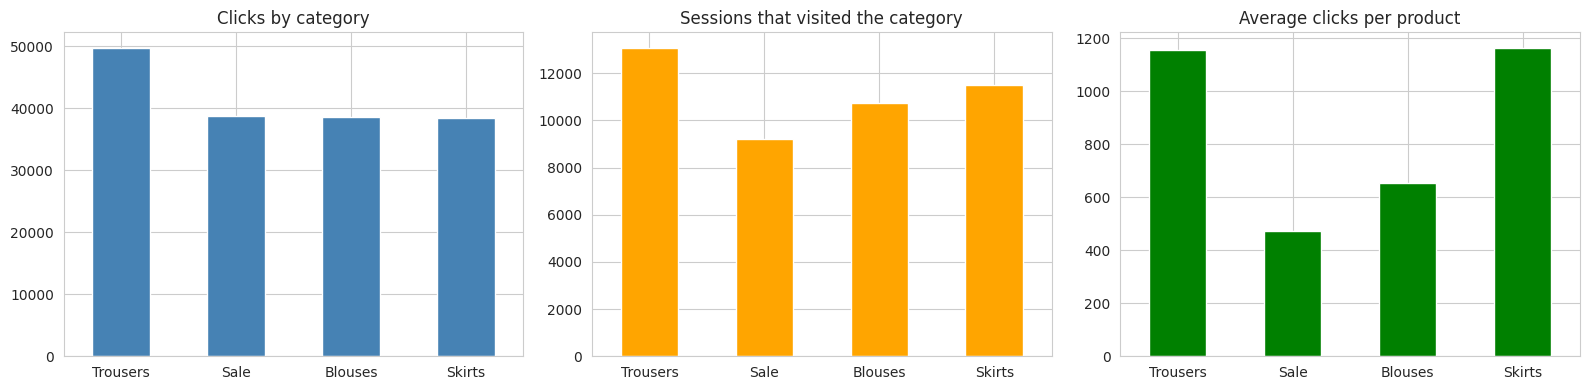

In [ ]:
clicks_by_cat = df["category_name"].value_counts()
sessions_by_cat = df.groupby("category_name")["session"].nunique().reindex(clicks_by_cat.index)
products_by_cat = df.groupby("category_name")["model"].nunique().reindex(clicks_by_cat.index)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
clicks_by_cat.plot(kind="bar", ax=ax[0], color="steelblue")
ax[0].set_title("Clicks by category")
sessions_by_cat.plot(kind="bar", ax=ax[1], color="orange")
ax[1].set_title("Sessions that visited the category")
(clicks_by_cat / products_by_cat).plot(kind="bar", ax=ax[2], color="green")
ax[2].set_title("Average clicks per product")
for a in ax:
    a.set_xlabel("")
    a.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig("figures/01_category_attention.png", dpi=150, bbox_inches="tight")
plt.show()

**What I observe:**



In [ ]:
# Q6 - compare the categories side by side
category_table = df.groupby("category_name").agg(
    clicks=("order", "count"),
    products=("model", "nunique"),
    avg_price=("price", "mean"),
    above_avg_price_clicks=("is_above_avg", "mean"),
    avg_page=("page", "mean")
)
category_table["above_avg_price_clicks"] = category_table["above_avg_price_clicks"] * 100
category_table

,clicks,products,avg_price,above_avg_price_clicks,avg_page
category_name,,,,,
Blouses,38577,59,40.29,57.09,1.99
Sale,38747,82,36.23,54.19,2.19
Skirts,38407,33,51.19,64.22,1.39
Trousers,49742,43,46.71,34.20,1.37


**Q6 answer:**

### 3.2 Which pages and page locations get the most clicks? (Q2, Q5 - 2 count plots)

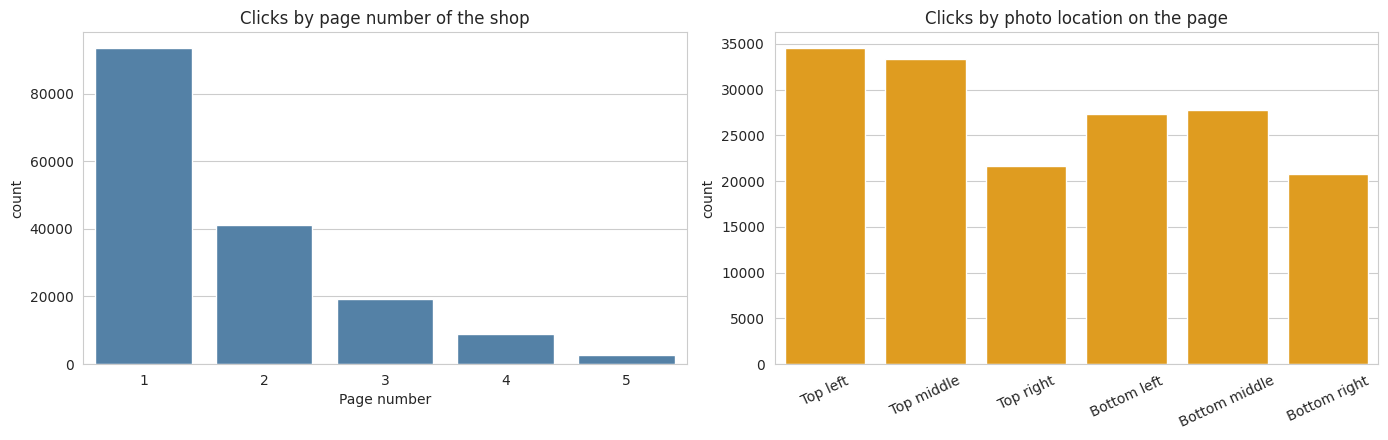

page
1   56.50
2   24.80
3   11.70
4    5.40
5    1.70
Name: proportion, dtype: float64


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.countplot(data=df, x="page", ax=ax[0], color="steelblue")
ax[0].set_title("Clicks by page number of the shop")
ax[0].set_xlabel("Page number")

sns.countplot(data=df, x="location_name", order=location_order, ax=ax[1], color="orange")
ax[1].set_title("Clicks by photo location on the page")
ax[1].set_xlabel("")
ax[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.savefig("figures/02_countplots_page_location.png", dpi=150, bbox_inches="tight")
plt.show()

print((df["page"].value_counts(normalize=True).sort_index() * 100).round(1))

**What I observe:**


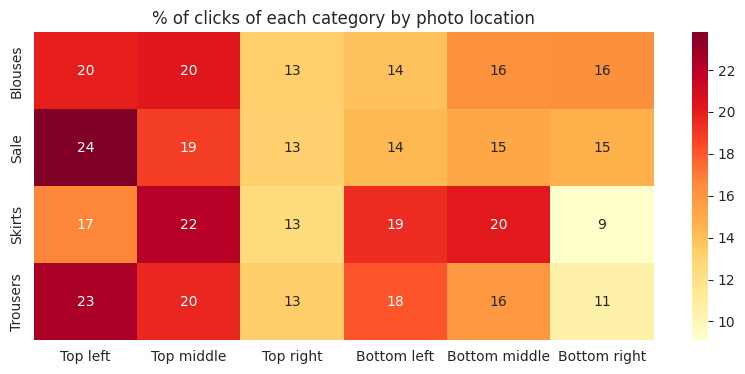

In [ ]:
# location x category (how clicks are spread over the page for each category)
loc_cat = pd.crosstab(df["category_name"], df["location_name"], normalize="index")[location_order] * 100

plt.figure(figsize=(10, 4))
sns.heatmap(loc_cat, annot=True, fmt=".0f", cmap="YlOrRd")
plt.title("% of clicks of each category by photo location")
plt.ylabel("")
plt.xlabel("")
plt.savefig("figures/03_heatmap_category_location.png", dpi=150, bbox_inches="tight")
plt.show()

**What I observe:**



### 3.3 Which countries are the most active? (Q4)

Share of clicks from the top country: 81.0 %
Number of countries: 47


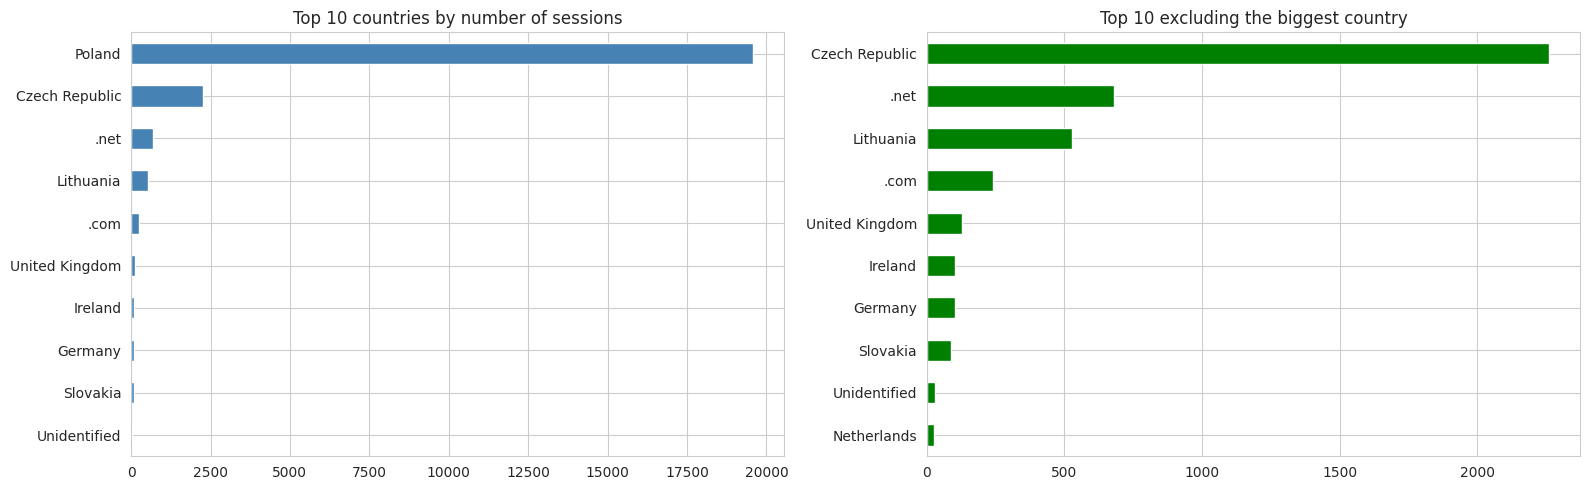

In [ ]:
country_sessions = sessions["country_name"].value_counts()
country_clicks = df["country_name"].value_counts()
print("Share of clicks from the top country:", round(country_clicks.iloc[0] / country_clicks.sum() * 100, 1), "%")
print("Number of countries:", len(country_sessions))

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
country_sessions.head(10).sort_values().plot(kind="barh", ax=ax[0], color="steelblue")
ax[0].set_title("Top 10 countries by number of sessions")
ax[0].set_ylabel("")

country_sessions.iloc[1:11].sort_values().plot(kind="barh", ax=ax[1], color="green")
ax[1].set_title("Top 10 excluding the biggest country")
ax[1].set_ylabel("")

plt.tight_layout()
plt.savefig("figures/04_country_sessions.png", dpi=150, bbox_inches="tight")
plt.show()

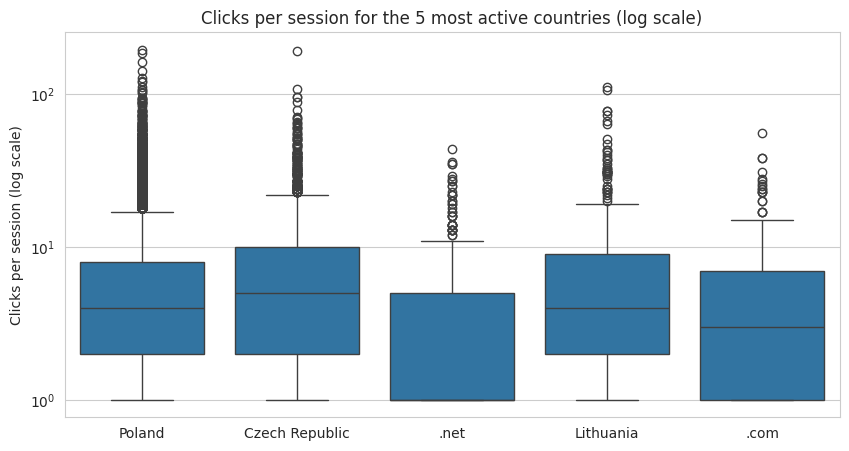

,count,mean,median
country_name,,,
Poland,19582,6.84,4.00
Czech Republic,2261,7.96,5.00
.net,681,3.70,1.00
Lithuania,527,7.76,4.00
.com,240,5.77,3.00


In [ ]:
top5 = country_sessions.head(5).index
plt.figure(figsize=(10, 5))
sns.boxplot(data=sessions[sessions["country_name"].isin(top5)], x="country_name", y="clicks", order=top5)
plt.yscale("log")
plt.title("Clicks per session for the 5 most active countries (log scale)")
plt.xlabel("")
plt.ylabel("Clicks per session (log scale)")
plt.savefig("figures/05_boxplot_country_clicks.png", dpi=150, bbox_inches="tight")
plt.show()

sessions[sessions["country_name"].isin(top5)].groupby("country_name")["clicks"].agg(["count", "mean", "median"]).loc[top5]

**What I observe:**



### 3.4 Does price affect behaviour? (Q3)

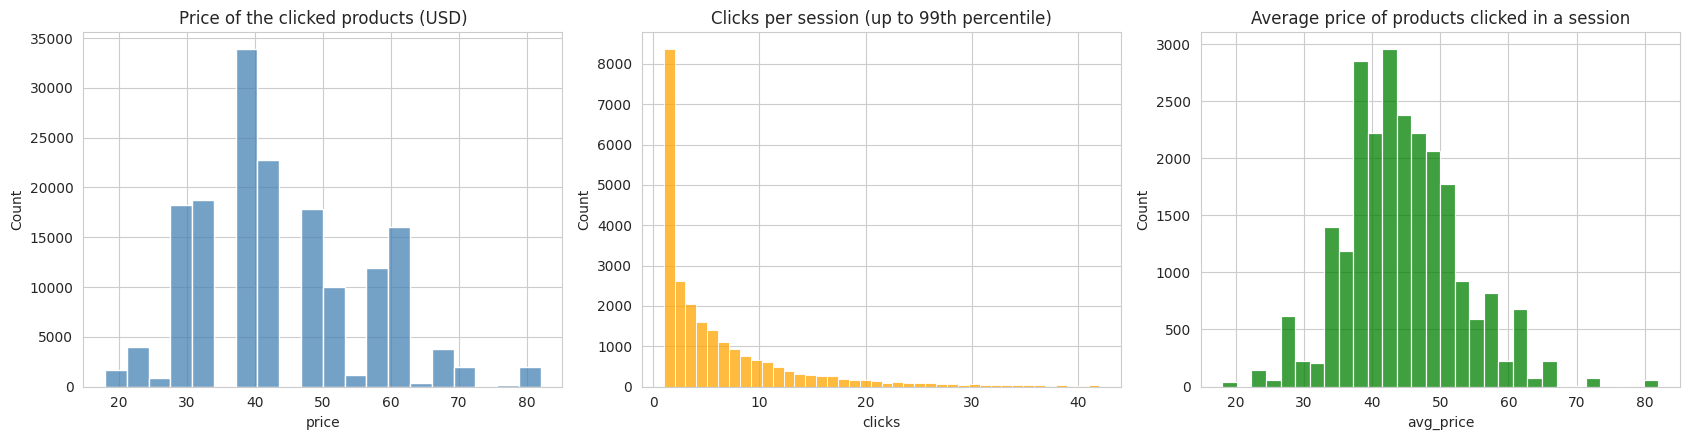

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

sns.histplot(df["price"], bins=20, ax=ax[0], color="steelblue")
ax[0].set_title("Price of the clicked products (USD)")

q = sessions[sessions["clicks"] <= sessions["clicks"].quantile(0.99)]
sns.histplot(q["clicks"], bins=40, ax=ax[1], color="orange")
ax[1].set_title("Clicks per session (up to 99th percentile)")

sns.histplot(sessions["avg_price"], bins=30, ax=ax[2], color="green")
ax[2].set_title("Average price of products clicked in a session")

plt.tight_layout()
plt.savefig("figures/06_histograms.png", dpi=150, bbox_inches="tight")
plt.show()

**What I observe:**



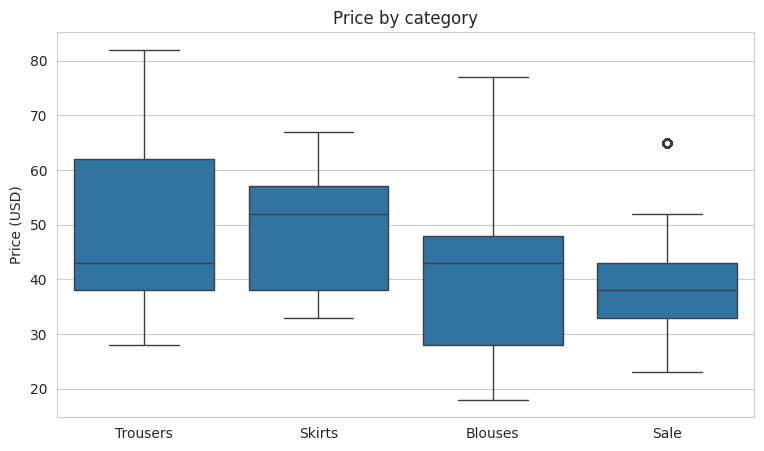

In [ ]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="category_name", y="price", order=["Trousers", "Skirts", "Blouses", "Sale"])
plt.title("Price by category")
plt.xlabel("")
plt.ylabel("Price (USD)")
plt.savefig("figures/07_boxplot_price_category.png", dpi=150, bbox_inches="tight")
plt.show()

**What I observe:**



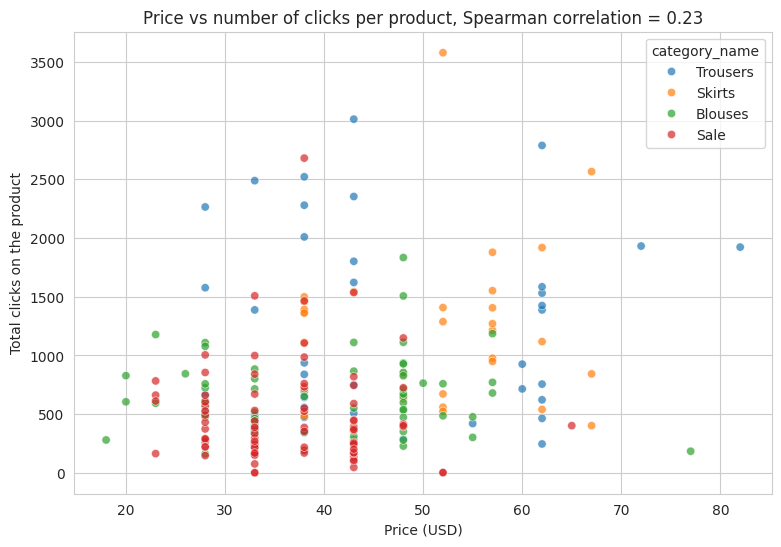

In [ ]:
# product level: do more expensive products get more or fewer clicks?
products = df.groupby("model").agg(
    clicks=("order", "count"),
    price=("price", "mean"),
    category_name=("category_name", "first")
).reset_index()

corr_value = products["clicks"].corr(products["price"], method="spearman")

plt.figure(figsize=(9, 6))
sns.scatterplot(data=products, x="price", y="clicks", hue="category_name", alpha=0.7)
plt.title("Price vs number of clicks per product, Spearman correlation = " + str(round(corr_value, 2)))
plt.xlabel("Price (USD)")
plt.ylabel("Total clicks on the product")
plt.savefig("figures/08_scatter_price_clicks.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
products["price_band"] = pd.cut(products["price"], bins=[0, 30, 40, 50, 60, 100],
                                labels=["Up to 30", "31-40", "41-50", "51-60", "Over 60"])
products.groupby("price_band").agg(number_of_products=("model", "count"),
                                   avg_clicks_per_product=("clicks", "mean"),
                                   median_clicks=("clicks", "median"))

,number_of_products,avg_clicks_per_product,median_clicks
price_band,,,
Up to 30,39,636.18,595.00
31-40,75,701.75,488.00
41-50,59,701.58,539.00
51-60,25,960.12,771.00
Over 60,19,"1,191.32","1,118.00"


In [ ]:
# clicks on products above vs not above the category average price
print(df["price_group"].value_counts(normalize=True).round(3) * 100)
print()
print("Average clicks per product:")
df.groupby("price_group")["order"].count() / df.groupby("price_group")["model"].nunique()

price_group
Above category average   51.20
Not above average        48.80
Name: proportion, dtype: float64

Average clicks per product:


,0
price_group,
Above category average,799.01
Not above average,727.73


**Q3 answer:**

### 3.5 Which products and colours are popular?

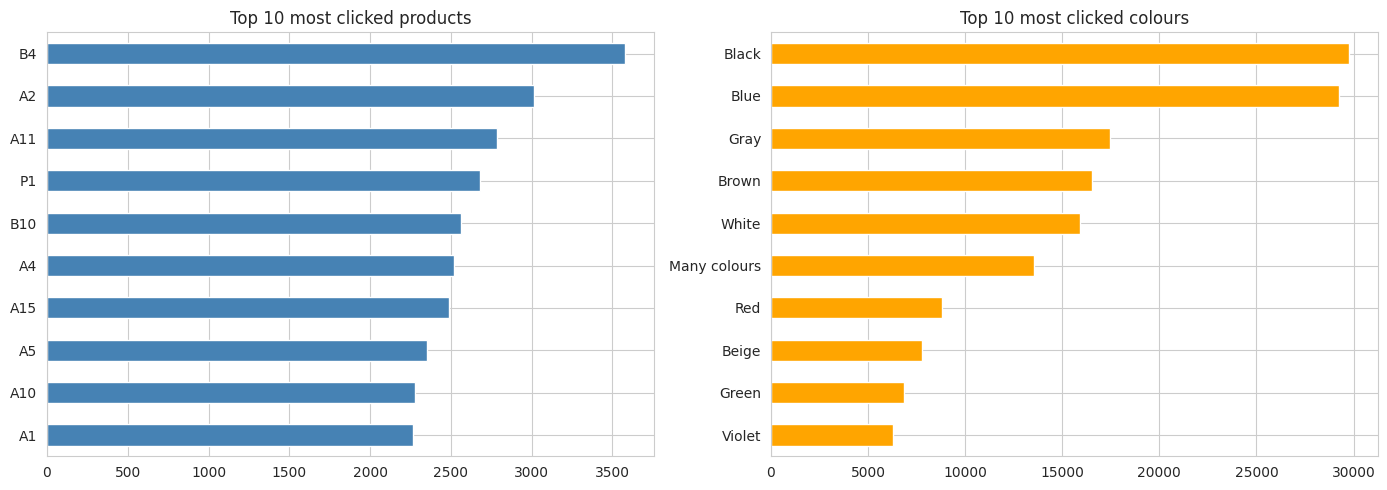

In [ ]:
top_products = df["model"].value_counts().head(10).sort_values()
top_colours = df["colour_name"].value_counts().head(10).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
top_products.plot(kind="barh", ax=ax[0], color="steelblue")
ax[0].set_title("Top 10 most clicked products")
ax[0].set_ylabel("")

top_colours.plot(kind="barh", ax=ax[1], color="orange")
ax[1].set_title("Top 10 most clicked colours")
ax[1].set_ylabel("")

plt.tight_layout()
plt.savefig("figures/09_top_products_colours.png", dpi=150, bbox_inches="tight")
plt.show()

**What I observe:**



### 3.6 How do users behave during a session?

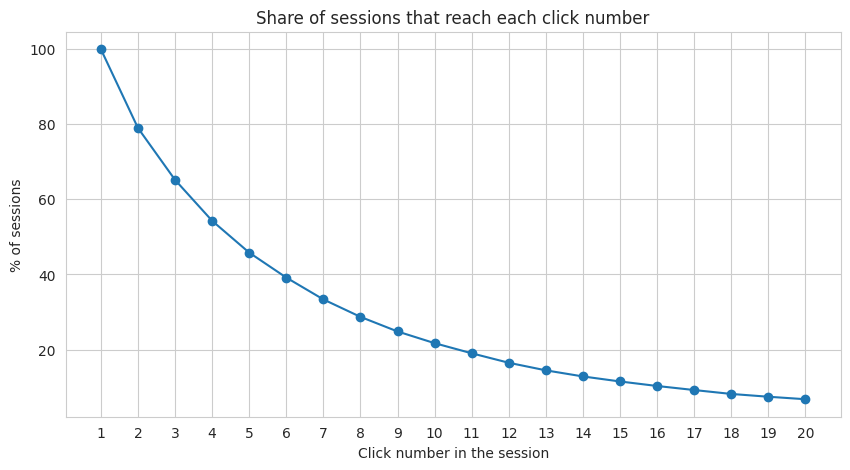

Sessions reaching click 5: 45.8 %
Sessions reaching click 10: 21.7 %


In [ ]:
# how many sessions are still going at click 1, 2, 3 ... ? (drop-off curve)
reached = df["order"].value_counts().sort_index()
reached = reached.loc[1:20]
percent_reached = reached / reached.iloc[0] * 100

plt.figure(figsize=(10, 5))
plt.plot(percent_reached.index, percent_reached.values, marker="o")
plt.title("Share of sessions that reach each click number")
plt.xlabel("Click number in the session")
plt.ylabel("% of sessions")
plt.xticks(range(1, 21))
plt.savefig("figures/10_dropoff_curve.png", dpi=150, bbox_inches="tight")
plt.show()

print("Sessions reaching click 5:", round(percent_reached.loc[5], 1), "%")
print("Sessions reaching click 10:", round(percent_reached.loc[10], 1), "%")

**What I observe:**


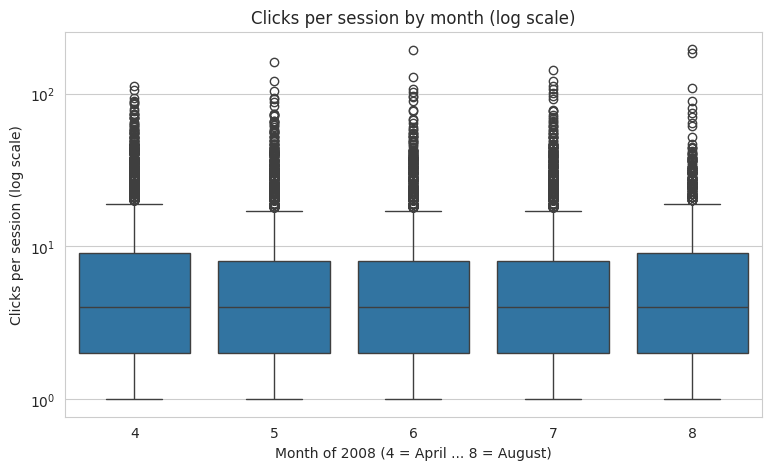

In [ ]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=sessions, x="month", y="clicks")
plt.yscale("log")
plt.title("Clicks per session by month (log scale)")
plt.xlabel("Month of 2008 (4 = April ... 8 = August)")
plt.ylabel("Clicks per session (log scale)")
plt.savefig("figures/11_boxplot_month.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.7 Activity over time (time series)

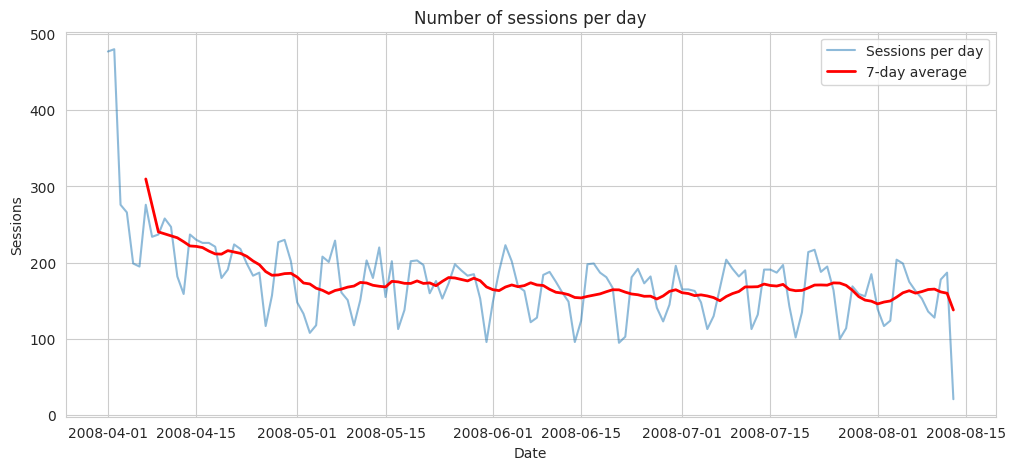

Last date in the data: 2008-08-13


In [ ]:
daily = sessions.groupby("date").size()
rolling = daily.rolling(7).mean()

plt.figure(figsize=(12, 5))
plt.plot(daily.index, daily.values, alpha=0.5, label="Sessions per day")
plt.plot(rolling.index, rolling.values, color="red", linewidth=2, label="7-day average")
plt.title("Number of sessions per day")
plt.xlabel("Date")
plt.ylabel("Sessions")
plt.legend()
plt.savefig("figures/12_daily_sessions.png", dpi=150, bbox_inches="tight")
plt.show()

print("Last date in the data:", daily.index.max().date())

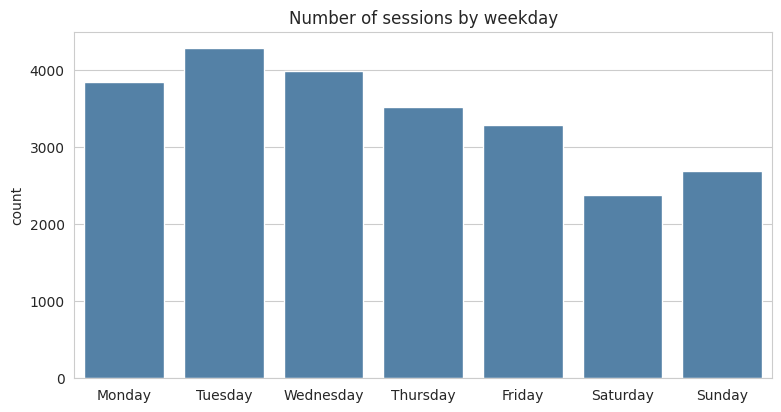

In [ ]:
plt.figure(figsize=(9, 4.5))
sns.countplot(data=sessions, x="weekday", order=weekday_order, color="steelblue")
plt.title("Number of sessions by weekday")
plt.xlabel("")
plt.savefig("figures/13_countplot_weekday.png", dpi=150, bbox_inches="tight")
plt.show()

**What I observe:**



### 3.8 Engagement as a proxy for conversion (Q7, Q8)

The dataset does not say if a user bought something. So I cannot measure real conversion. As a **proxy** I call a session **highly engaged** if it has more clicks than 75% of all sessions. These are users who looked at many products, so they are more likely to be serious shoppers. This is only an assumption, not a real purchase.

In [ ]:
limit = sessions["clicks"].quantile(0.75)
sessions["engaged"] = sessions["clicks"] > limit
print("Engaged means more than", limit, "clicks")
print("Share of engaged sessions:", round(sessions["engaged"].mean() * 100, 1), "%")

Engaged means more than 8.0 clicks
Share of engaged sessions: 24.8 %


In [ ]:
# do engaged sessions look different? (I do not use clicks, pages or products here, because engagement is made from clicks)
compare = sessions.groupby("engaged")[["avg_price", "above_avg_share", "sale_share", "categories"]].mean()
compare["above_avg_share"] = compare["above_avg_share"] * 100
compare["sale_share"] = compare["sale_share"] * 100
compare

,avg_price,above_avg_share,sale_share,categories
engaged,,,,
False,44.63,51.85,17.34,1.53
True,43.60,51.02,24.75,2.82


**What I observe:**



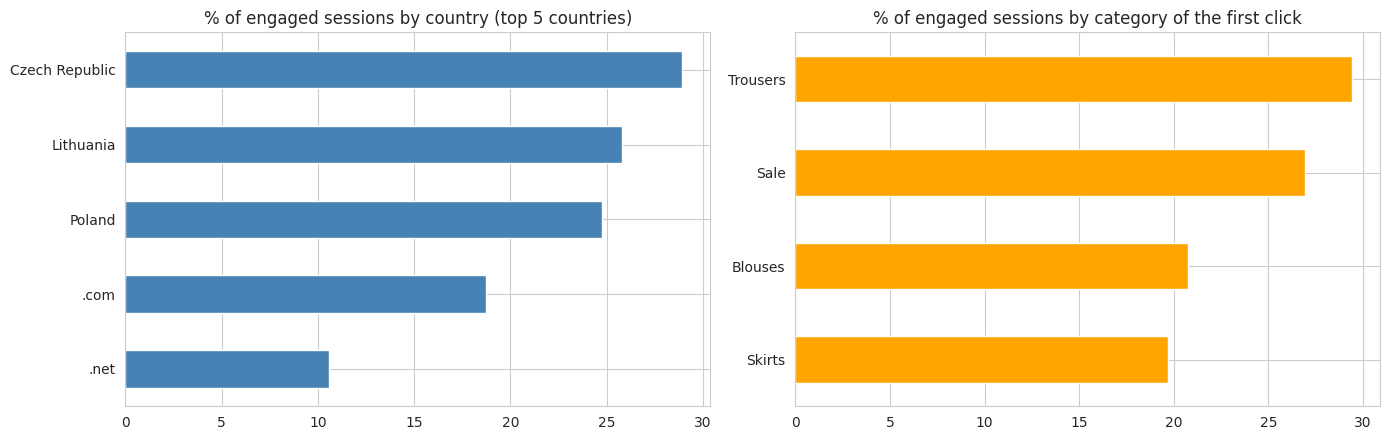

In [ ]:
top5 = country_sessions.head(5).index
by_country = sessions[sessions["country_name"].isin(top5)].groupby("country_name")["engaged"].mean() * 100
by_first_category = sessions.groupby("first_category_name")["engaged"].mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
by_country.sort_values().plot(kind="barh", ax=ax[0], color="steelblue")
ax[0].set_title("% of engaged sessions by country (top 5 countries)")
ax[0].set_ylabel("")
by_first_category.sort_values().plot(kind="barh", ax=ax[1], color="orange")
ax[1].set_title("% of engaged sessions by category of the first click")
ax[1].set_ylabel("")

plt.tight_layout()
plt.savefig("figures/14_engagement_country_category.png", dpi=150, bbox_inches="tight")
plt.show()

**What I observe:**



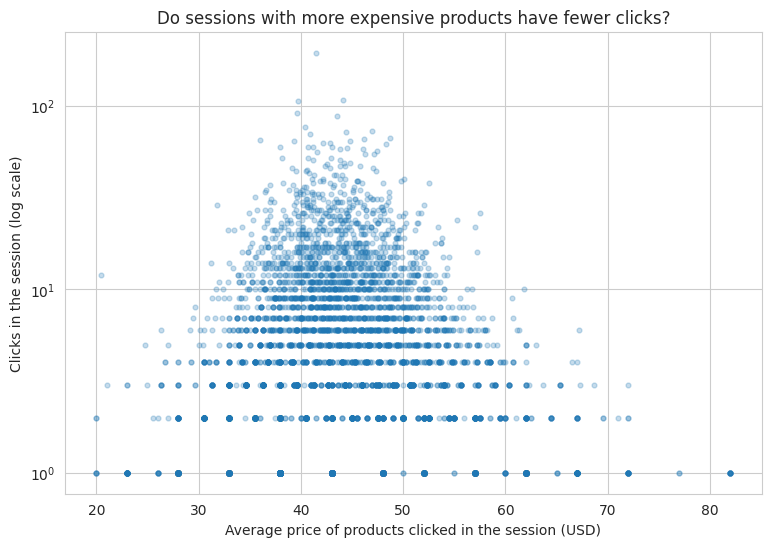

In [ ]:
sample = sessions.sample(5000, random_state=1)

plt.figure(figsize=(9, 6))
plt.scatter(sample["avg_price"], sample["clicks"], alpha=0.25, s=12)
plt.yscale("log")
plt.xlabel("Average price of products clicked in the session (USD)")
plt.ylabel("Clicks in the session (log scale)")
plt.title("Do sessions with more expensive products have fewer clicks?")
plt.savefig("figures/15_scatter_price_session_clicks.png", dpi=150, bbox_inches="tight")
plt.show()

**What I observe:**



### 3.9 Correlation analysis

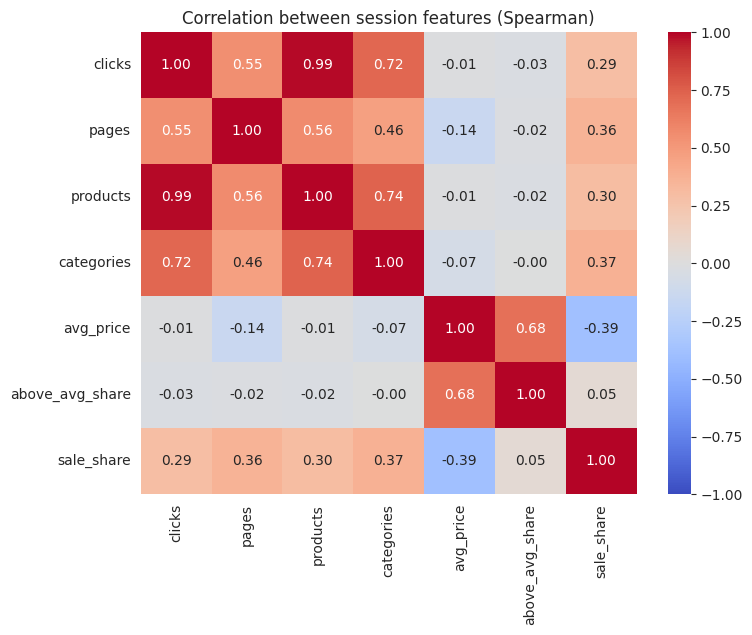

In [ ]:
features = ["clicks", "pages", "products", "categories", "avg_price", "above_avg_share", "sale_share"]
corr = sessions[features].corr(method="spearman")

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between session features (Spearman)")
plt.savefig("figures/16_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

*I used Spearman correlation because the clicks per session are very skewed with some extreme values.*

**What I observe:**



## 4. Chart checklist (assignment requirements)

| Required | Where in this notebook |
|---|---|
| 3 histograms | 3.4 (price per click, clicks per session, average session price) |
| 3 box plots | 3.3 (clicks by country), 3.4 (price by category), 3.6 (clicks by month) |
| 3 bar charts | 3.1 (category), 3.3 (countries), 3.5 (products, colours), 3.8 (engagement) |
| 2 count plots | 3.2 (page, location), 3.7 (weekday) |
| 2 scatter plots | 3.4 (price vs clicks per product), 3.8 (price vs clicks per session) |
| 1 correlation heatmap | 3.9 |
| 1 time-series chart | 3.7 (daily sessions) |
| 2 additional visualizations | 3.2 (category x location heatmap), 3.6 (drop-off curve) |

## 5. Insights, Recommendations and Limitations

### Key insights

1. **Categories:** Trousers received the most clicks (49,742), while sale products had the lowest average clicks per product (473).
2. **Pages and locations:** Page 1 received 56.5% of clicks. Top-left and top-middle positions attracted the most attention.
3. **Countries:** Poland accounted for 81.5% of sessions, followed by the Czech Republic at 9.4%.
4. **Price:** Products above $60 averaged 1,191 clicks per product, but price and clicks had only a weak positive correlation (0.23).
5. **Session behaviour:** 21% of sessions had only one click, and only 21.7% reached ten clicks.
6. **Engagement:** Highly engaged sessions represented 24.8% of sessions and visited more categories (2.82 versus 1.53). Actual purchases could not be measured.

### Recommendations

1. Prioritize popular products on the first page and in prominent photo positions.
2. Improve navigation and recommendations to reduce early session drop-off.
3. Promote sale products and investigate opportunities in other countries.
4. Track purchases and checkout events to measure actual conversion.

### Limitations

- No purchase data was available to measure actual conversion.
- Data covered April–August 2008, with August incomplete.
- The dataset represents one clothing shop and may not generalize to other shops.
- Most sessions came from Poland.
- Correlation does not imply causation.

### Resume description

Analyzed 165K+ clickstream records across 24K shopping sessions using Python, Pandas, NumPy, Matplotlib and Seaborn to identify browsing patterns and recommend improvements to product placement and marketing.